<a href="https://colab.research.google.com/github/js-DigitalSurfer/ML/blob/main/05_Klasyfikator_Bayesa_irysy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Naiwny klasyfikator Bayesa

Rozważymy klasyczny problem klasyfikacji odmian irysów na podstawie cech płatków. Jest to klasyczny już problem, często wykorzystywany przy porównywaniu różnych technik klasyfikacji. Więcej o pochodzeniu tych danych i problemie można przeczytać tu: [Iris_flower_data](https://en.wikipedia.org/wiki/Iris_flower_data_set)

W tym notatniku użyjemy naiwnego klasyfikatora Bayesa. Kod napiszemy w oparciu o implementacje klasyfikatora Bayesa z biblioteki [scikit-learn](http://scikit-learn.org/stable/about.html#citing-scikit-learn)

Zaczerpniemy stamtąd:
* obiekt klasyfikatora [GaussianNB](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.GaussianNB.html),
* zbiór danych,
* funkcje do oceny jakości klasyfikacji

### Przygotowanie środowiska programistycznego

In [1]:
import numpy as np
from termcolor import colored

from sklearn import datasets
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from scipy.stats import multivariate_normal

import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd

## Wczytanie danych do analizy

Zbiór danych ``Iris`` jest dostępny w bibliotece sklearn jako jeden z wielu standardowych zbiorów [testowych](https://scikit-learn.org/stable/datasets/toy_dataset.html).

In [2]:
#Wczytywanie danych
iris = datasets.load_iris()

#Wypisywanie zawartości wczytanego obiektu
print(dir(iris))

['DESCR', 'data', 'data_module', 'feature_names', 'filename', 'frame', 'target', 'target_names']


## Analiza zawartości danych

**Proszę** wypisać:

* nazwy gatunków,
* kodowanie gatunków, czyli liczby przypisane do nazw gatunków ```target```,
* nazwy zmiennych opisujących gatunki ```feature_names```,

**Wskazówka**: informacje o zbiorze uzyskujemy traktując go jak słownik:
```Python
print(iris['filename'])
```

In [3]:
print(iris['target_names'])
print(iris['target'])
print(iris['feature_names'])


print(iris['DESCR'])

['setosa' 'versicolor' 'virginica']
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correla

## Przepisane danych do obiektu Pandas DataFrame

**Proszę** utworzyć obiekt DataFrame zawierający własności ("features") oraz etykiety ("label")
* przypisać poprawne nazwy kolumn: ```columns=iris.feature_name```,
* dodać do obiektu DataFrame kolumnę ```label``` zawierającą etykiety,
* wypisać własności przykładu o indeksie 5
* sprawdzić jaki gatunek odpowiada wartości etykiety przykładu o indeksie 5.

**Wskazówka:** można skorzystać z funkcji DataFrame.loc(index)

Oczekiwany wynik:
```Python
sepal length (cm)    5.4
sepal width (cm)     3.9
petal length (cm)    1.7
petal width (cm)     0.4
label                0.0
Name: 5, dtype: float64
Gatunek przykładu o indeksie 5: setosa
```

In [4]:
# 1. Tworzymy tabelkę z wymiarami płatków
df = pd.DataFrame(iris['data'], columns=iris['feature_names'])

# 2. Dorzucamy kolumnę z numerkami gatunków (0, 1, 2)
df['label'] = iris['target']

# 3. Wyciągamy z tabelki cały wiersz o indeksie 5 i go wypisujemy
example_5 = df.loc[5]
print(example_5)

# 4. Sprawdzamy, jak nazywa się gatunek ukryty pod numerkiem z wiersza nr 5
label_number = int(example_5['label'])

example_species = iris['target_names'][label_number]

print(colored("Gatunek przykładu o indeksie 5:","blue"), example_species)


sepal length (cm)    5.4
sepal width (cm)     3.9
petal length (cm)    1.7
petal width (cm)     0.4
label                0.0
Name: 5, dtype: float64
Gatunek przykładu o indeksie 5: setosa


## Analiza wizualna danych.

Pierwszy krok przy analizie danych z użyciem dowolnego algorytmu to ich inspekcja. Korzystając z metod klasy `DataFrame`.

**Proszę:**
* narysować jednowymiarowe histogramy dla wszystkich zmiennych (kolumn obiektu DataFrame)

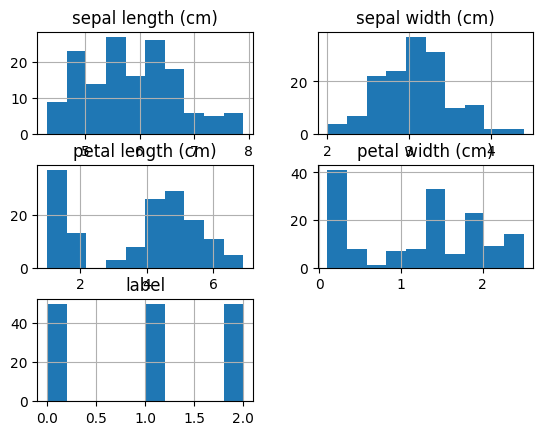

In [5]:
# Rysujemy histogramy dla wszystkich kolumn z naszej tabeli
df.hist()

# Pokazujemy wykres na ekranie
plt.show()

Naszym zadaniem jest rozdzielenie gatunków na podstawie własności. Poniższa komórka rysuje rozkłady (histogramy) własności w podziale na  gatunki.

**Proszę:**

* na podstawie histogramów proszę zidentyfikować cechy, które najlepiej odróżniają gatunki.

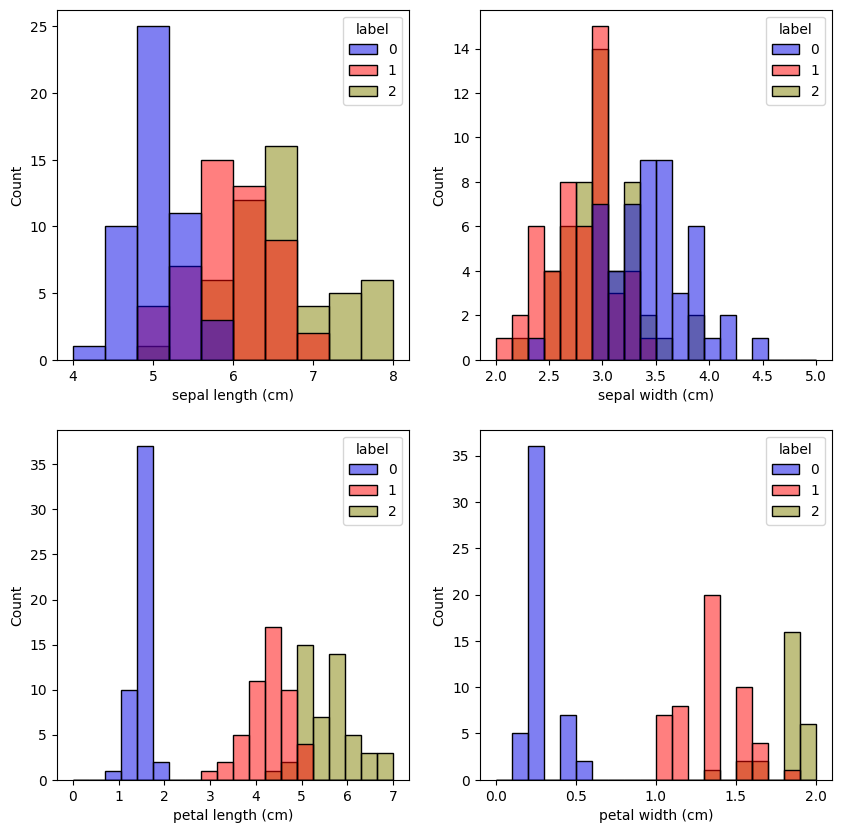

In [6]:
fig, axes = plt.subplots(2,2, figsize=(10,10))
color_map = {-1: (1, 1, 1), 0: (0, 0, .9), 1: (1, 0, 0), 2: (.5, .5, 0)}

sns.histplot(data=df, x="sepal length (cm)", hue="label", binrange=(4,8),palette=color_map, bins=10, ax=axes[0,0]);
sns.histplot(data=df, x="sepal width (cm)", hue="label", palette=color_map, binrange=(2,5), bins=20, ax=axes[0,1]);
sns.histplot(data=df, x="petal length (cm)", hue="label", palette=color_map, binrange=(0,7), bins=20, ax=axes[1,0]);
sns.histplot(data=df, x="petal width (cm)", hue="label", palette=color_map, binrange=(0,2), bins=20, ax=axes[1,1]);

## Wykres skrzypcowy ("violin plot")

Histogramy dla poszczególnych gatunków się nakładają częściowo. Inny sposób wizualizacji to wykres skrzypcowy (ang. "violin plot"). Poniższa komórka
rysuje wykresy skrzypcowe dla poszczególnych cech z podziałem na gatunki.

**Proszę:**

* na podstawie rysunków zidentyfikować cechy, które najlepiej odróżniają gatunki.

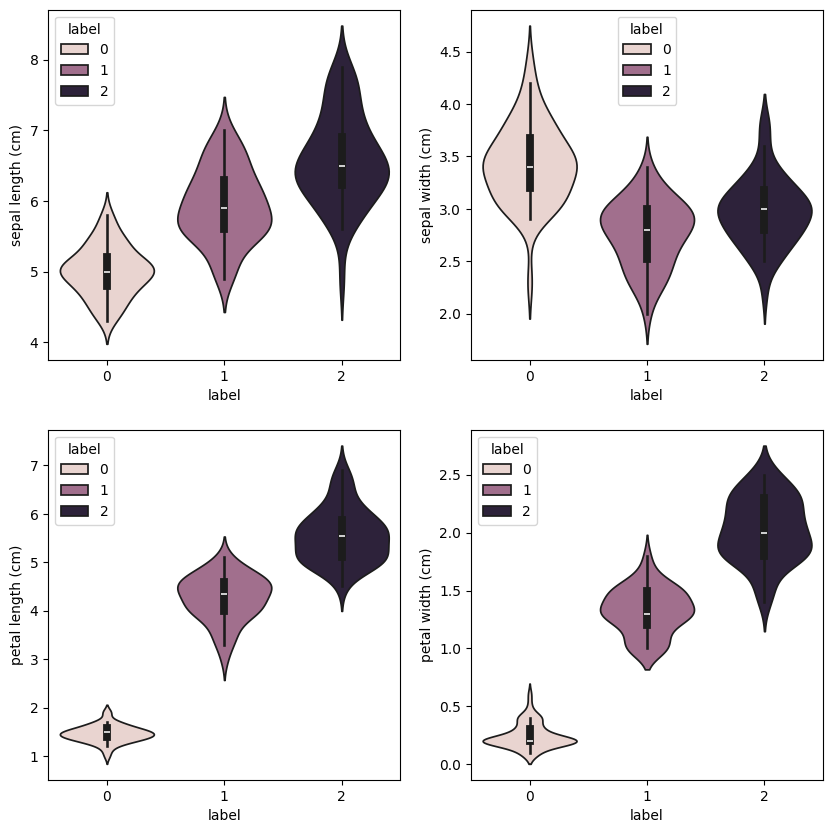

In [7]:
fig, axes = plt.subplots(2,2, figsize=(10,10))

for index, columnName in enumerate(df.columns[0:4]):
    sns.violinplot(data=df, x="label", hue="label", y=columnName,ax=axes[(int)(index/2),index%2]);

## Analiza dwuwymiarowa

Rysunki narysowane do tej pory były jednowymiarowe. Kolejny krok to wizualna analiza korelacji między cechami. Korelację między cechami można zwizualizować na wiele sposobów. Poniższa komórka rysuje:

* macierz kowariancji między wszystkimi kolumnami danych włączając etykiety
* dwuwymiarowe rozkłady dla par cech

Więcej przykładów wizualizacji można znaleźć w dokumentacji: [link](https://seaborn.pydata.org/tutorial/axis_grids.html).

                   sepal length (cm)  sepal width (cm)  petal length (cm)  \
sepal length (cm)           1.000000         -0.117570           0.871754   
sepal width (cm)           -0.117570          1.000000          -0.428440   
petal length (cm)           0.871754         -0.428440           1.000000   
petal width (cm)            0.817941         -0.366126           0.962865   
label                       0.782561         -0.426658           0.949035   

                   petal width (cm)     label  
sepal length (cm)          0.817941  0.782561  
sepal width (cm)          -0.366126 -0.426658  
petal length (cm)          0.962865  0.949035  
petal width (cm)           1.000000  0.956547  
label                      0.956547  1.000000  


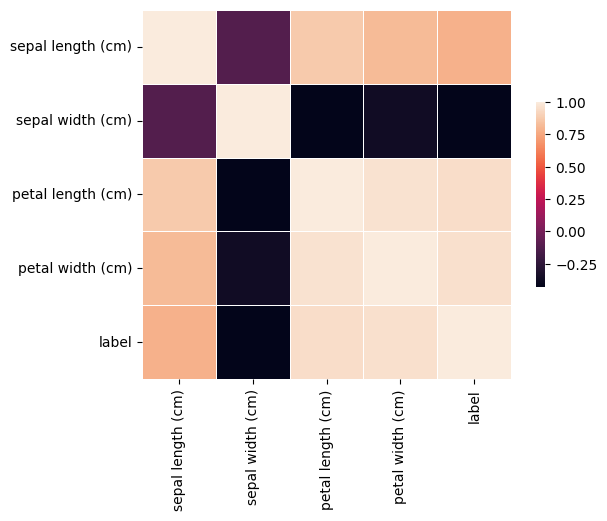

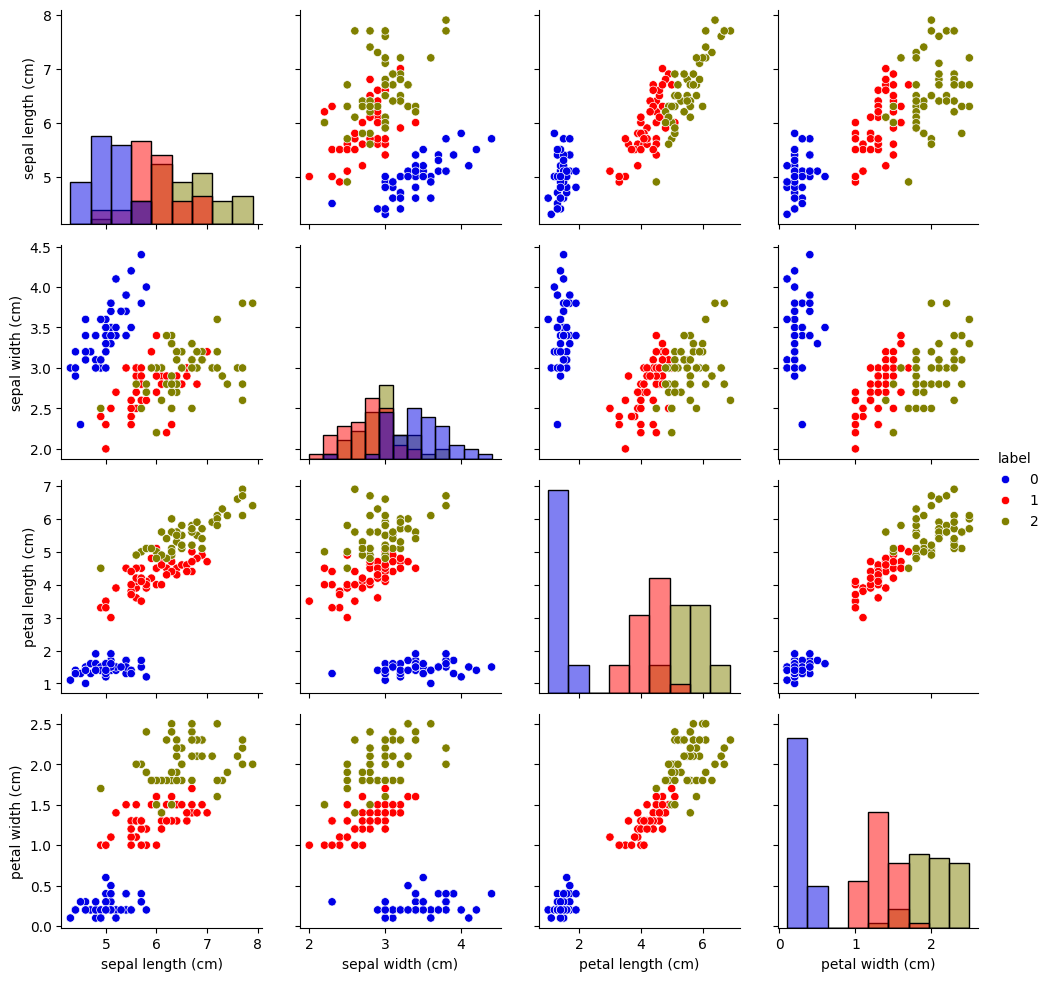

In [8]:
corelationMatrix = df.corr()
print(corelationMatrix)

cmap = sns.diverging_palette(230, 20, as_cmap=True)
sns.heatmap(corelationMatrix, square=True, linewidths=.5, cbar_kws={"shrink": .5});

graph = sns.PairGrid(df, hue="label", palette=color_map)
graph.map_diag(sns.histplot)
graph.map_offdiag(sns.scatterplot);
graph.add_legend();

## Przygotowanie danych wejściowych (ang. preprocessing)

Od tego momentu, aby ułatwić analizę wyniku działania modelu ograniczymy się do dwu cech - wtedy będzie można narysować podział na gatunki na płaszczyźnie.

Standardową procedurą obróbki danych przed utworzeniem modelu jest ich normalizacja, najlepiej do zakresu [-1,1] lub [0,1].
Znormalizujemy wartości cech według wzoru:

\begin{equation}
x_{norm} = \frac{x - \mu_{x}}{\sigma_{x}}
\end{equation}

**Proszę:**

* utworzyć nowy obiekt DataFrame ```df_normalized``` zawierający znormalizowane kolumny własności oraz etykiety:
* utworzyć obiekt DataFrame ```df_subset``` zawierający tylko wybrane cechy, oraz etykiety:
  
  ```Python
  ["sepal width (cm)","petal length (cm)", "label"]
  ```
<br></br>
* wypisać zawartość obiektów ```df_normalized``` i ```df_subset```. Czy widać efekt normalizacji w wartościach opisujących dane?

**Uwaga:** proszę nie normalizować wartości etykiet

In [9]:
# 1. Normalizujemy cechy (odejmujemy średnią i dzielimy przez odchylenie standardowe)
# Robimy to tylko dla kolumn z wymiarami, bez kolumny 'label'
df_features = df.drop(columns=['label'])
df_normalized = (df_features - df_features.mean()) / df_features.std()

# Przywracamy nienaruszoną kolumnę z etykietami do znormalizowanej tabeli
df_normalized['label'] = df['label']

# 2. Tworzymy podzbiór (subset) zawierający tylko dwie wybrane cechy oraz etykiety
selected_columns = ["sepal width (cm)", "petal length (cm)", "label"]
df_subset = df_normalized[selected_columns]

print(colored("Normalized dataset:","blue"))
print(df_normalized.describe())
print(colored("Normalized dataset with only two features:","blue"))
print(df_subset.describe())

Normalized dataset:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count       1.500000e+02      1.500000e+02       1.500000e+02   
mean       -1.515825e-15     -1.823726e-15      -1.515825e-15   
std         1.000000e+00      1.000000e+00       1.000000e+00   
min        -1.863780e+00     -2.425820e+00      -1.562342e+00   
25%        -8.976739e-01     -5.903951e-01      -1.222456e+00   
50%        -5.233076e-02     -1.315388e-01       3.353541e-01   
75%         6.722490e-01      5.567457e-01       7.602115e-01   
max         2.483699e+00      3.080455e+00       1.779869e+00   

       petal width (cm)       label  
count      1.500000e+02  150.000000  
mean      -8.526513e-16    1.000000  
std        1.000000e+00    0.819232  
min       -1.442245e+00    0.000000  
25%       -1.179859e+00    0.000000  
50%        1.320673e-01    1.000000  
75%        7.880307e-01    2.000000  
max        1.706379e+00    2.000000  
Normalized dataset with only two features:
       se

**Proszę:**
* narysować dwuwymiarowe rozkłady dla par cech dla znormalizowanych dla DataFrame z dwiema cechami.

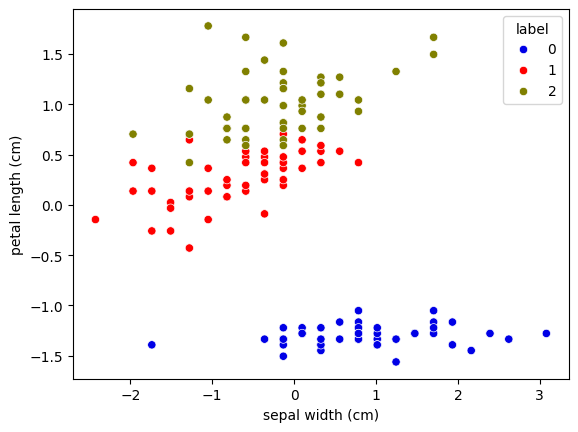

In [10]:
# Rysujemy wykres punktowy, gdzie kropki dostają kolory na podstawie gatunku (label)
sns.scatterplot(data=df_subset, x="sepal width (cm)", y="petal length (cm)", hue="label", palette=color_map)

# Pokazujemy wykres na ekranie
plt.show()

## Definicja i trening klasyfikatora

W tym notatniku użyjemy klasyfikatora [naive bayes](https://scikit-learn.org/stable/modules/naive_bayes.html) w wersji gausowskiej.

**Proszę:**

* utworzyć obiekt ```gnb``` klasy [GaussianNB](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.GaussianNB.html)
* przeprowadzić trening z użyciem funkcji ```fit()```

In [11]:
# 1. Wyciągamy cechy (X) i etykiety (Y) z naszej zredukowanej tabeli
X = df_subset[["sepal width (cm)", "petal length (cm)"]]
Y = df_subset["label"]

# 2. Tworzymy czysty model klasyfikatora
gnb = GaussianNB()

# 3. Trenujemy model (czyli dajemy detektywowi dane do nauki)
gnb.fit(X, Y)
print(colored("Accuracy on train dataset: ","blue"), gnb.score(X,Y))

Accuracy on train dataset:  0.92


**Proszę:**


* wypisać wartości parametrów modelu: średnie i odchylenia standardowe rozkładów Gaussa. Średnie znajdują się w polu  ```gnb.theta_```, a wariancje
  w ```gnb.var_```
* wypisać średnie i odchylenia standardowe rozkładów cech w podziale na gatunki obliczone z danych
* porównać uzyskane wartości. Czy liczby są zgodne z oczekiwaniami?

**Wskazówka:** proszę skorzystać z grupowania danych: `DataFrame.groupby()`.

Oczekiwany wynik dla parametrów z modelu:
```Python
Mean:
 [[ 0.85041372 -1.30063009]
 [-0.65922358  0.28437121]
 [-0.19119013  1.01625888]]
Sigma:
 [[0.86093968 0.09738785]
 [0.71270594 0.26351816]
 [0.73246175 0.30949324]]
```

In [12]:
# 1. Wyciągamy parametry wyuczone przez model gnb
print("Mean (z modelu):")
print(gnb.theta_)

# Wariancja to sigma kwadrat, więc odchylenie standardowe (sigma) to pierwiastek z wariancji
print("Sigma (z modelu):")
print(np.sqrt(gnb.var_))

# 2. Liczymy te same parametry bezpośrednio z tabeli za pomocą groupby
print("\nŚrednie obliczone z danych:")
print(df_subset.groupby('label').mean())

print("\nOdchylenia standardowe obliczone z danych:")
print(df_subset.groupby('label').std())

Mean (z modelu):
[[ 0.85041372 -1.30063009]
 [-0.65922358  0.28437121]
 [-0.19119013  1.01625888]]
Sigma (z modelu):
[[0.86093968 0.09738785]
 [0.71270594 0.26351816]
 [0.73246175 0.30949324]]

Średnie obliczone z danych:
       sepal width (cm)  petal length (cm)
label                                     
0              0.850414          -1.300630
1             -0.659224           0.284371
2             -0.191190           1.016259

Odchylenia standardowe obliczone z danych:
       sepal width (cm)  petal length (cm)
label                                     
0              0.869680           0.098377
1              0.719942           0.266194
2              0.739898           0.312635


### Porównanie dopasowanych rozkładów z danymi.
Komórki poniżej zawierają funkcje:

* ```plot_2d_gaussian(mean, covariance, axis)``` - funkcja która rysuje dwuwymiarowy rozkład Gaussa o średniej ```mean``` i diagonalnej macierzy kowariancji ```np.diag(cov)``` na obszarze danym przez obiekt ```axis```,
* ```plot_2d_divison(model, axis)``` - funkcja która rysuje kontury podziału na klasy na podstawie modelu ```model``` na obszarze danym przez obiekt ```axis```.

In [13]:
def plot_2d_gaussian(mean, cov, axis):
    xx, yy = np.mgrid[-3:3:0.1, -3:2:0.1]
    pos = np.dstack((xx, yy))
    zz = multivariate_normal.pdf(pos, mean=mean, cov=np.diag(cov))
    axis.contour(xx, yy, zz, 10)

def plot_2d_divison(model, axis):
    xx, yy = np.mgrid[-4:4:0.01, -4:4:0.01]
    pos = np.c_[xx.ravel(), yy.ravel()]
    zz = model.predict(pos)
    zz = np.reshape(zz, xx.shape)
    axis.contour(xx, yy, zz, cmap=plt.cm.Paired)

Poniższa komórka rysuje:

* dwuwymiarowy rozkład danych dla analizowanego zbioru. Punkty są pokolorowane według przynależności do gatunku,
* funkcja ```plot_2d_gaussian(mean, covariance, axis)``` rysuje na tym samym rysunku poziomnice rozkładów Gaussa modelu ```gnb = GaussianNB()```.

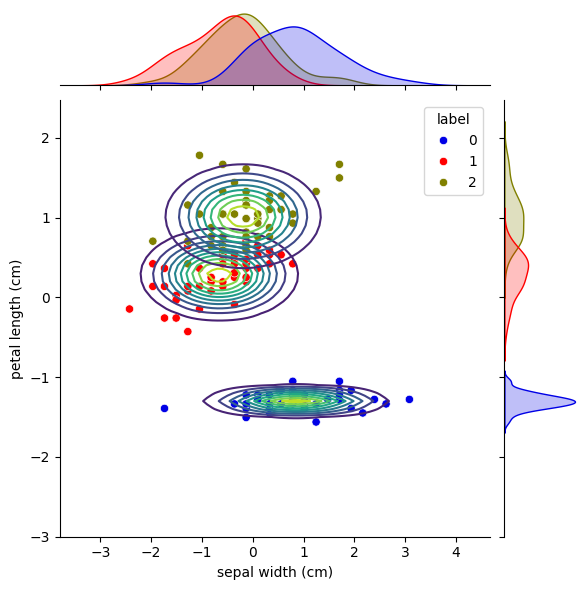

In [14]:
graph = sns.jointplot(x="sepal width (cm)", y="petal length (cm)", data=df_subset, hue="label", palette=color_map)

for classNumber in range(0,3):
    plot_2d_gaussian(mean=gnb.theta_[classNumber], cov=np.diag(gnb.var_[classNumber]), axis=graph.ax_joint)

**Proszę:**

* korzystając z funkcji ```sns.jointplot``` narysować dwuwymiarowy rozkład danych dla analizowanego zbioru. Punkty powinny być pokolorowane według przynależności do gatunku,
* korzystając z funkcji ```plot_2d_divison(model, axis)``` nanieść granice podziału na gatunki.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(


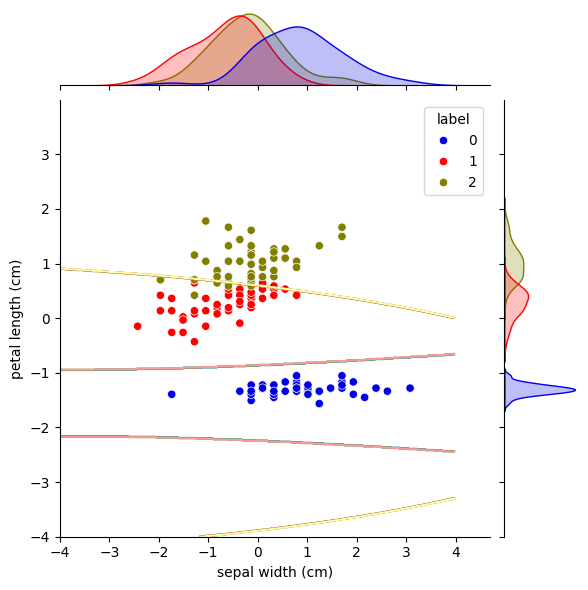

In [15]:
# 1. Rysujemy bazowy wykres punktowy z kropkami w kolorach gatunków
graph = sns.jointplot(x="sepal width (cm)", y="petal length (cm)", data=df_subset, hue="label", palette=color_map)

# 2. Nanosimy linie graniczne wyznaczone przez nasz wytrenowany model gnb
plot_2d_divison(model=gnb, axis=graph.ax_joint)

# 3. Wyświetlamy gotowy rysunek
plt.show()

## Analiza jakości modelu
Korzystając z walidacji krzyżowej przeprowadzimy analizę miar jakości modeli. Skorzystamy z funkcji opisanych w rozdziale [Model evaluation](http://scikit-learn.org/stable/modules/model_evaluation.html) dokumentacji pakietu scikit-learn.

**Proszę:**

* przejrzeć listę dostępnych metryk i upewnić się, co dokładnie zwracają poszczególne funkcje,
* porównać definicje z scikit-learn z definicjami z [wykładu](https://brain.fuw.edu.pl/edu/index.php/Uczenie_maszynowe_i_sztuczne_sieci_neuronowe/Wyk%C5%82ad_Ocena_jako%C5%9Bci_klasyfikacji),
* uzupełnić kod funkcji ```printScores(model, X, Y)```, która przyjmuje ```model```, cechy ```X``` oraz etykiety ```Y``` i wypisuje
  raport o klasyfikacji oraz macierz pomyłek
  
Oczekiwany wynik:
```Python
Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.85      0.92      0.88        50
           2       0.91      0.84      0.87        50

    accuracy                           0.92       150
   macro avg       0.92      0.92      0.92       150
weighted avg       0.92      0.92      0.92       150

Confusion matrix:
[[50  0  0]
 [ 0 46  4]
 [ 0  8 42]]
```

In [16]:
def printScores(model, X, Y):
    # 1. Prosimy model o wygenerowanie przewidywań dla wszystkich kwiatków
    Y_pred = model.predict(X)

    # 2. Tworzymy i wypisujemy szczegółowy raport (Precision, Recall, F1)
    print("Classification report:")
    print(classification_report(Y, Y_pred))

    # 3. Tworzymy i wypisujemy tabelę pomyłek
    print("Confusion matrix:")
    print(confusion_matrix(Y, Y_pred))

# Wywołujemy funkcję dla naszego modelu gnb i danych z podzbioru
printScores(gnb, X, Y)

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.85      0.92      0.88        50
           2       0.91      0.84      0.88        50

    accuracy                           0.92       150
   macro avg       0.92      0.92      0.92       150
weighted avg       0.92      0.92      0.92       150

Confusion matrix:
[[50  0  0]
 [ 0 46  4]
 [ 0  8 42]]


## Porównanie  modeli

**Proszę:**

Stworzyć trzy klasyfikatory:

* korzystający z cech ```["sepal width (cm)","petal length (cm)"]``` (nasz dotychczasowy model): ```gnb_features_1_2```
* korzystający tylko z cech ```["sepal length (cm)","sepal width (cm)"]```: ```gnb_features_0_1```
* korzystający ze wszystkich czterech cech: ```gnb_features_all```
* dla każdego z modeli wypisać wartości miar jakości i na ich podstawie stwierdzić który model jest najlepszy

**Pytanie:** Czy powyższe kryterium wyboru najlepszego modelu jest w pełni poprawne?

In [17]:
# Model 1: sepal width + petal length (nasz dotychczasowy, zredukowany)
X1 = df_normalized[["sepal width (cm)", "petal length (cm)"]]
Y1 = df_normalized["label"]
gnb_features_1_2 = GaussianNB()
gnb_features_1_2.fit(X1, Y1)
printScores(gnb_features_1_2, X1, Y1)

print(colored("Model using","blue"), "sepal length and sepal width", colored("features:", "blue"))
# Model 2: sepal length + sepal width (same cechy kielicha - te, które mocno się mieszały)
X2 = df_normalized[["sepal length (cm)", "sepal width (cm)"]]
Y2 = df_normalized["label"]
gnb_features_0_1 = GaussianNB()
gnb_features_0_1.fit(X2, Y2)
printScores(gnb_features_0_1, X2, Y2)

print(colored("Model using","blue"), "all", colored("features:", "blue"))
# Model 3: Wszystkie cztery dostępne cechy
X_all = df_normalized.drop(columns=['label'])
Y_all = df_normalized["label"]
gnb_features_all = GaussianNB()
gnb_features_all.fit(X_all, Y_all)
printScores(gnb_features_all, X_all, Y_all)

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.85      0.92      0.88        50
           2       0.91      0.84      0.88        50

    accuracy                           0.92       150
   macro avg       0.92      0.92      0.92       150
weighted avg       0.92      0.92      0.92       150

Confusion matrix:
[[50  0  0]
 [ 0 46  4]
 [ 0  8 42]]
Model using sepal length and sepal width features:
Classification report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99        50
           1       0.65      0.74      0.69        50
           2       0.70      0.62      0.66        50

    accuracy                           0.78       150
   macro avg       0.78      0.78      0.78       150
weighted avg       0.78      0.78      0.78       150

Confusion matrix:
[[49  1  0]
 [ 0 37 13]
 [ 0 19 31]]
Model using all features:
Class

## Analiza wpływu normalizacji danych.

**Proszę:**

* wytrenować model na wszystkich cechach, ale korzystając z oryginalnych danych - bez normalizacji wartości cech,
* wypisać wartości miar jakości dla uzyskanego modelu

**Pytanie:** Czy normalizacja wpływa na wydajność naszego modelu?

In [18]:
# 1. Wyciągamy cechy (X) i etykiety (Y) z oryginalnej tabeli (bez normalizacji)
X_raw = df.drop(columns=['label'])
Y_raw = df["label"]

# 2. Tworzymy nowy model i trenujemy go na surowych danych
gnb_raw = GaussianNB()
gnb_raw.fit(X_raw, Y_raw)

# 3. Wypisujemy raport jakości
printScores(gnb_raw, X_raw, Y_raw)

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.94      0.94      0.94        50
           2       0.94      0.94      0.94        50

    accuracy                           0.96       150
   macro avg       0.96      0.96      0.96       150
weighted avg       0.96      0.96      0.96       150

Confusion matrix:
[[50  0  0]
 [ 0 47  3]
 [ 0  3 47]]


# Zadanie domowe

## Dekorelacja zmiennych.
Niektóre zmienne są silnie skorelowane - algorytm "naiwny" nie radzi sobie z tym dobrze.
Proszę wytrenować modele na następujących danych  normalizacji:

* zawierających dwie silnie skorelowane cechy:
```Python
["petal length (cm)","petal width (cm)"]
```
* zawierających ich zdekorelowane funkcje $x$ i $y$ będące sumą i różnicą skorelowanych zmiennych:
```Python
x = "petal length (cm)" + "petal width (cm)"
y = "petal length (cm)" - "petal width (cm)"
```
* proszę narysować dwuwymiarowe rozkłady dla zmiennych $x$ i $y$
* czy model używający zmiennych $x$ i $y$ jest lepszy/gorszy od modeli trenowanych wcześniej? Odpowiedź uzasadnij.

1. Model ze skorelowanymi cechami:
Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.94      0.94      0.94        50
           2       0.94      0.94      0.94        50

    accuracy                           0.96       150
   macro avg       0.96      0.96      0.96       150
weighted avg       0.96      0.96      0.96       150

Confusion matrix:
[[50  0  0]
 [ 0 47  3]
 [ 0  3 47]]


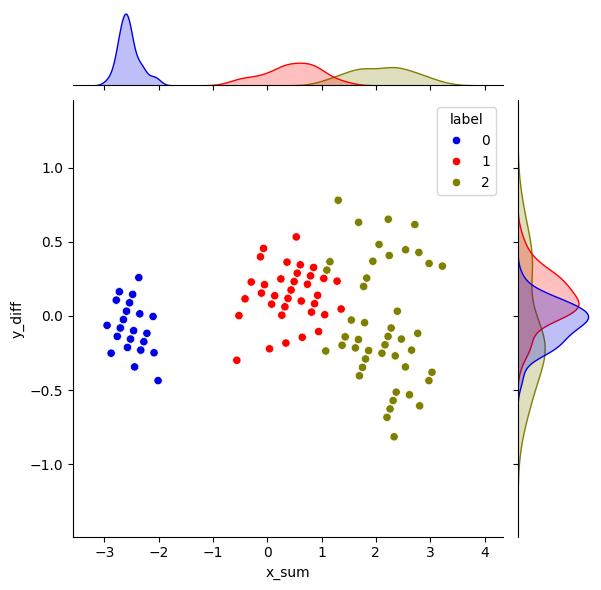

2. Model po dekorelacji (Suma i Różnica):
Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.96      0.98      0.97        50
           2       0.98      0.96      0.97        50

    accuracy                           0.98       150
   macro avg       0.98      0.98      0.98       150
weighted avg       0.98      0.98      0.98       150

Confusion matrix:
[[50  0  0]
 [ 0 49  1]
 [ 0  2 48]]


In [19]:
# 1. Zbiór ze skorelowanymi cechami (płatki)
X_corr = df_normalized[["petal length (cm)", "petal width (cm)"]]
Y_corr = df_normalized["label"]

gnb_corr = GaussianNB()
gnb_corr.fit(X_corr, Y_corr)
print(colored("1. Model ze skorelowanymi cechami:", "blue"))
printScores(gnb_corr, X_corr, Y_corr)

# 2. Tworzymy nowe, zdekorelowane cechy (Suma i Różnica)
df_decorr = pd.DataFrame()
df_decorr['x_sum'] = df_normalized["petal length (cm)"] + df_normalized["petal width (cm)"]
df_decorr['y_diff'] = df_normalized["petal length (cm)"] - df_normalized["petal width (cm)"]
df_decorr['label'] = df_normalized["label"]

# 3. Rysujemy dwuwymiarowy rozkład dla nowych zmiennych x i y
graph_decorr = sns.jointplot(x="x_sum", y="y_diff", data=df_decorr, hue="label", palette=color_map)
plt.show()

# 4. Trenujemy model na zdekorelowanych cechach
X_decorr = df_decorr[["x_sum", "y_diff"]]
Y_decorr = df_decorr["label"]

gnb_decorr = GaussianNB()
gnb_decorr.fit(X_decorr, Y_decorr)
print(colored("2. Model po dekorelacji (Suma i Różnica):", "blue"))
printScores(gnb_decorr, X_decorr, Y_decorr)